# Loans: contractual schedules and projected receipts

Build a EUR 100,000 loan using the library's existing coupons and redemptions.
The builder fixes the contractual principal schedule. The pricer resolves index
observations and applies a separate prepayment function to expected receipts.

This walkthrough uses `Request.Cashflows` throughout. It covers fixed, floating
and mixed coupons, repayment structures, prepayment, both fair-rate schedule
modes, quote risk, credit and refinancing. Market inputs are illustrative and
shared with `cargo run -p valuation-loans`.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import quantsupport as qs
from market_data import load_loan_market

pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
reference = "2026-02-24"
principal = 100_000.0
market = load_loan_market()
known_fixings = qs.FixingStore()

def market_context(scenarios=None, include_credit=False, fixings=None):
    return qs.PricingContext(
        market.quotes, market.curves,
        credit_curves=market.credit_curves if include_credit else [],
        fixings=known_fixings if fixings is None else fixings,
        csa_policy=market.csa_policy, scenarios=scenarios,
    )

contract_terms = dict(
    start_date=reference, maturity_date="2028-02-24", notional=principal,
    currency=qs.Currency.EUR, discount_index=qs.MarketIndex.ESTR,
    payment_frequency=qs.Frequency.Monthly, day_counter=qs.DayCounter.Actual360,
    calendar="TARGET", fixing_lag=2,
    business_day_convention=qs.BusinessDayConvention.Following,
)
fixed_rate = qs.LoanRateDefinition.fixed(0.06)
french = qs.LoanRepaymentStructure.french()
pricer = qs.LoanPricer()
requests = [qs.Request.Value, qs.Request.Cashflows, qs.Request.Sensitivities]

## 1. Fixed contractual principal

French amortization uses a 6% initial coupon and the actual accrual intervals to
produce a level instalment. Its opening notionals and redemptions are ordinary
numbers, independent of market curves. The Python constructor delegates schedule
construction to `MakeLoan`; the Rust instrument can also accept a supplied leg.

Enter the pricing context to construct curves, then request cashflows from the
pricer. Value is the PV of future receipts, excluding the initial advance.

In [2]:
fixed = qs.Loan(identifier="FIXED", rate=fixed_rate, repayment=french, **contract_terms)
fixed_snapshot = fixed.to_dict()
with market_context() as context:
    fixed_result = pricer.evaluate(qs.Trade(fixed, reference), context, requests)
    fixed_cashflows = fixed_result.cashflows
    discounted = sum(row.amount * context.curve("ESTR").discount_factor(row.payment_date)
                     for row in fixed_cashflows.itertuples(index=False))
assert math.isclose(discounted, fixed_result.price, abs_tol=1e-7)
assert set(fixed_cashflows.type) == {"FixedRateCoupon", "Redemption"}
assert fixed.to_dict() == fixed_snapshot

fixed_payments = fixed_cashflows.pivot_table(index="payment_date", columns="type",
                                           values="amount", aggfunc="sum", fill_value=0)
fixed_payments["total"] = fixed_payments.sum(axis=1)
fixed_payments["closing_principal"] = principal - fixed_payments.Redemption.cumsum()
assert math.isclose(fixed_payments.Redemption.sum(), principal, abs_tol=1e-7)
assert fixed_payments.total.max() - fixed_payments.total.min() < 1e-7
display(fixed_payments.head())
print(f"Receipt PV: EUR {fixed_result.price:,.2f}; PV minus advance: EUR {fixed_result.price - principal:,.2f}")

type,FixedRateCoupon,Redemption,total,closing_principal
payment_date,,,,
2026-03-24,466.666667,"3,968.130057","4,434.796724","96,031.869943"
2026-04-24,496.164661,"3,938.632063","4,434.796724","92,093.237880"
2026-05-25,460.466189,"3,974.330535","4,434.796724","88,118.907345"
2026-06-24,455.281021,"3,979.515703","4,434.796724","84,139.391642"
2026-07-24,420.696958,"4,014.099766","4,434.796724","80,125.291876"


Receipt PV: EUR 103,212.08; PV minus advance: EUR 3,212.08


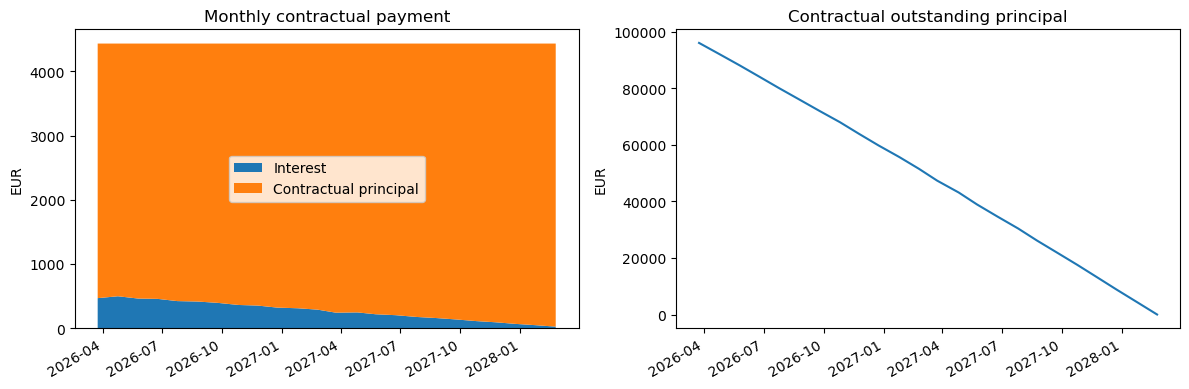

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
dates = pd.to_datetime(fixed_payments.index)
axes[0].stackplot(dates, fixed_payments.FixedRateCoupon, fixed_payments.Redemption,
                  labels=["Interest", "Contractual principal"])
axes[0].set(title="Monthly contractual payment", ylabel="EUR")
axes[0].legend()
axes[1].plot(dates, fixed_payments.closing_principal)
axes[1].set(title="Contractual outstanding principal", ylabel="EUR")
figure.autofmt_xdate()
figure.tight_layout()
plt.show()

## 2. Builder repayment structures

Bullet repayment keeps the full principal outstanding until maturity. A 25%
balloon leaves that residual for the final payment. These structures determine
contractual redemptions; prepayment is a separate pricing input.

In [4]:
structures = {
    "French": fixed,
    "Bullet": qs.Loan(identifier="BULLET", rate=fixed_rate,
                      repayment=qs.LoanRepaymentStructure.bullet(), **contract_terms),
    "Balloon 25%": qs.Loan(identifier="BALLOON", rate=fixed_rate,
                           repayment=qs.LoanRepaymentStructure.balloon(0.25), **contract_terms),
}
comparison = []
with market_context() as context:
    for label, instrument in structures.items():
        result = pricer.evaluate(qs.Trade(instrument, reference), context, ["Value", "Cashflows"])
        payments = result.cashflows.groupby("payment_date").amount.sum()
        redemptions = result.cashflows.loc[result.cashflows.type == "Redemption", "amount"]
        assert math.isclose(redemptions.sum(), principal, abs_tol=1e-7)
        comparison.append(dict(structure=label, first_payment=payments.iloc[0],
                               final_payment=payments.iloc[-1], receipt_pv=result.price))
display(pd.DataFrame(comparison))

,structure,first_payment,final_payment,receipt_pv
0,French,"4,434.796724","4,434.796724","103,212.081102"
1,Bullet,466.666667,"100,516.666667","106,062.426498"
2,Balloon 25%,"3,452.804265","28,452.804265","103,924.315189"


## 3. Monthly payments with annual observations

EURIBOR12m's observation frequency comes from its index metadata. Each monthly
coupon carries the relevant annual reset request and the full 12-month index
observation interval. The two-day business lag makes the first fixing historical.

An explicit 5% initial all-in `amortization_rate` fixes the floating loan's
principal schedule. Later fixings change interest; they leave that schedule in
place. A mixed loan uses its initial 4% coupon for amortization and switches the
coupon definition at the specified payment boundary.

In [5]:
floating = qs.Loan(
    identifier="FLOATING", rate=qs.LoanRateDefinition.floating("EURIBOR12m", 0.01),
    repayment=french, amortization_rate=0.05, **contract_terms,
)
mixed = qs.Loan(
    identifier="MIXED", rate=qs.LoanRateDefinition.mixed(0.04, "2027-02-24", "EURIBOR12m", 0.01),
    repayment=french, **contract_terms,
)
observations = floating.fixing_requests()
assert len(observations) == 2
assert observations.start_date.tolist() == [reference, "2027-02-24"]
for row in observations.itertuples(index=False):
    if row.fixing_date < reference:
        known_fixings.add(row.market_index, row.fixing_date, 0.04)
display(observations)

with market_context() as context:
    floating_result = pricer.evaluate(qs.Trade(floating, reference), context, requests)
    mixed_result = pricer.evaluate(qs.Trade(mixed, reference), context, requests)
coupons = floating_result.cashflows.loc[floating_result.cashflows.type == "FloatingRateCoupon"]
assert coupons.fixing.iloc[:12].tolist() == [0.04] * 12
display(coupons.iloc[[0, 11, 12, -1]])
try:
    with market_context(fixings=qs.FixingStore()) as context:
        context.evaluate(qs.Trade(floating, reference), ["Cashflows"])
except qs.QuantSupportError as error:
    print("Missing historical observation is reported:", error)
else:
    raise AssertionError("Historical reset silently forecast")

,market_index,fixing_date,start_date,end_date
0,EURIBOR12m,2026-02-20,2026-02-24,2027-02-24
1,EURIBOR12m,2027-02-22,2027-02-24,2028-02-24


,payment_date,type,amount,fixing,accrual_period,currency,caplet_strike,floorlet_strike,leg_index
0,2026-03-24,FloatingRateCoupon,388.888889,0.040000,0.077778,EUR,None,None,0
22,2027-02-24,FloatingRateCoupon,238.593374,0.040000,0.086111,EUR,None,None,0
24,2027-03-24,FloatingRateCoupon,193.145552,0.038441,0.077778,EUR,None,None,0
46,2028-02-24,FloatingRateCoupon,18.231084,0.038441,0.086111,EUR,None,None,0


Missing historical observation is reported: Not found error: Index EURIBOR12m not found in fixings data.


## 4. Prepayment changes expected receipts

`PrepaymentModelConfiguration.cpr(0.25)` defines the prepayment function. A
regular monthly interval converts annual CPR to `1 - (1 - CPR)**(1/12)`.
The pricer applies it after scheduled principal. Expected subsequent receipts
shrink proportionally; the stored contractual coupons and redemptions stay fixed.

Cashflow reporting uses existing types. Leg 0 contains scheduled receipts,
leg 1 prepayment redemptions, and leg 2 recovery amounts.

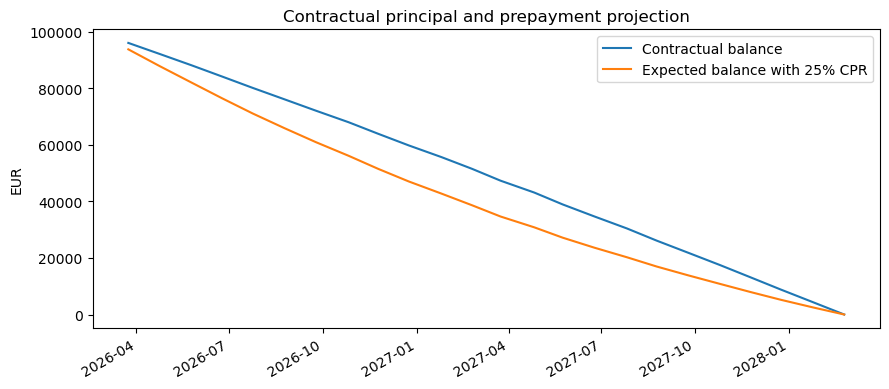

,payment_date,type,amount,fixing,accrual_period,currency,caplet_strike,floorlet_strike,leg_index
48,2026-03-24,Redemption,"2,274.843674",None,0.000000,EUR,None,None,1
49,2026-04-24,Redemption,"2,129.866355",None,0.000000,EUR,None,None,1
50,2026-05-25,Redemption,"1,989.675043",None,0.000000,EUR,None,None,1
51,2026-06-24,Redemption,"1,854.816093",None,0.000000,EUR,None,None,1
52,2026-07-24,Redemption,"1,724.485516",None,0.000000,EUR,None,None,1


In [6]:
prepaying = qs.Loan(identifier="CPR", rate=fixed_rate, repayment=french,
                    prepayment=qs.PrepaymentModelConfiguration.cpr(0.25), **contract_terms)
prepaying_snapshot = prepaying.to_dict()
with market_context() as context:
    prepayment_result = pricer.evaluate(qs.Trade(prepaying, reference), context, requests)
prepayment_cashflows = prepayment_result.cashflows
assert prepaying.to_dict() == prepaying_snapshot
assert set(prepayment_cashflows.type) == {"FixedRateCoupon", "Redemption"}
assert math.isclose(prepayment_cashflows.loc[prepayment_cashflows.type == "Redemption", "amount"].sum(),
                    principal, abs_tol=1e-7)
assert (prepayment_cashflows.leg_index == 1).any()
expected_principal = prepayment_cashflows.loc[prepayment_cashflows.type == "Redemption"].groupby("payment_date").amount.sum()
expected_balance = principal - expected_principal.cumsum()
figure, axis = plt.subplots(figsize=(9, 4))
axis.plot(pd.to_datetime(fixed_payments.index), fixed_payments.closing_principal, label="Contractual balance")
axis.plot(pd.to_datetime(expected_balance.index), expected_balance, label="Expected balance with 25% CPR")
axis.set(title="Contractual principal and prepayment projection", ylabel="EUR")
axis.legend()
figure.autofmt_xdate()
figure.tight_layout()
plt.show()
display(prepayment_cashflows.loc[prepayment_cashflows.leg_index == 1].head())

## 5. Fair rate: preserve or rebuild the schedule

`LoanPricer(recompute_schedule=False)` solves a coupon or spread using existing
principal amounts. `recompute_schedule=True` regenerates the builder's repayment
schedule for every candidate. This option affects `FairRate`; ordinary valuation
always uses the already created schedule.

Reprice both solutions independently. For the preserving mode, use the original
initial amortization rate. For the rebuilding mode, use the solved fixed coupon
or the first EURIBOR fixing plus the solved spread.

In [7]:
par_checks = []
with market_context() as context:
    for rebuild in [False, True]:
        fair_pricer = qs.LoanPricer(recompute_schedule=rebuild)
        for label, instrument, original_rate in [("Fixed", fixed, 0.06), ("Floating", floating, 0.05)]:
            fair = fair_pricer.evaluate(qs.Trade(instrument, reference), context, ["FairRate"]).fair_rate
            is_floating = label == "Floating"
            candidate_rate = qs.LoanRateDefinition.floating("EURIBOR12m", fair) if is_floating else qs.LoanRateDefinition.fixed(fair)
            initial_rate = (0.04 + fair if is_floating else fair) if rebuild else original_rate
            candidate = qs.Loan(identifier=f"PAR-{label}-{rebuild}", rate=candidate_rate,
                                repayment=french, amortization_rate=initial_rate, **contract_terms)
            candidate_result = fair_pricer.evaluate(qs.Trade(candidate, reference), context, ["Value", "Cashflows"])
            assert math.isclose(candidate_result.price, principal, abs_tol=1e-5)
            par_checks.append(dict(loan=label, recompute_schedule=rebuild,
                                   fair_coupon_or_spread=fair, repriced_pv=candidate_result.price))
display(pd.DataFrame(par_checks))

,loan,recompute_schedule,fair_coupon_or_spread,repriced_pv
0,Fixed,False,0.029395,"100,000.000000"
1,Floating,False,-0.010201,"100,000.000000"
2,Fixed,True,0.029398,"100,000.000001"
3,Floating,True,-0.010202,"100,000.000000"


## 6. Quote risk without changing contractual principal

Sensitivities are derivatives per unit market quote. Multiply by `1e-4` for the
first-order PV change from a one-basis-point increase. Verify one derivative
with central differences and check that bumped markets retain identical
contractual principal receipts.

In [8]:
risk = floating_result.sensitivities.copy()
risk["pv_change_for_plus_1bp_eur"] = risk.value * 1e-4
display(risk)
pillar = risk.loc[risk.value.abs().idxmax(), "pillar"]
derivative = risk.loc[risk.pillar == pillar, "value"].iloc[0]
bump = 1e-5
prices = []
principal_receipts = []
for change in [bump, -bump]:
    scenario = qs.Scenario(pillar, change, qs.ScenarioType.Absolute)
    with market_context(scenarios=[scenario]) as context:
        result = pricer.evaluate(qs.Trade(floating, reference), context, ["Value", "Cashflows"])
    prices.append(result.price)
    principal_receipts.append(result.cashflows.loc[result.cashflows.type == "Redemption", "amount"].tolist())
finite_difference = (prices[0] - prices[1]) / (2 * bump)
assert principal_receipts[0] == principal_receipts[1]
assert math.isclose(derivative, finite_difference, rel_tol=1e-3, abs_tol=0.1)
print(f"{pillar}: AAD {derivative:,.6f}; central difference {finite_difference:,.6f}")

,pillar,value,pv_change_for_plus_1bp_eur
0,FixedRateDeposit_EUR_ESTR_1D,-66.939615,-0.006694
1,FixedRateDeposit_EUR_ESTR_1Y,"-50,206.409975",-5.020641
2,FixedRateDeposit_EUR_ESTR_2Y,"-51,588.393867",-5.158839
3,FixedRateDeposit_EUR_ESTR_3Y,0.000000,0.000000
4,FixedRateDeposit_EUR_EURIBOR12m_1D,0.000000,0.000000
5,FixedRateDeposit_EUR_EURIBOR12m_1Y,"-26,988.384692",-2.698838
6,FixedRateDeposit_EUR_EURIBOR12m_2Y,"51,951.947099",5.195195
7,FixedRateDeposit_EUR_EURIBOR12m_3Y,0.000000,0.000000


FixedRateDeposit_EUR_EURIBOR12m_2Y: AAD 51,951.947099; central difference 51,951.947100


## 7. Borrower credit and recovery

The pricer weights future receipts by borrower survival conditional on the
valuation date. Default between payments pays 40% recovery of opening principal
at the period-end payment date. This discrete recovery convention is an
approximation. The contractual leg remains unchanged.

In [9]:
credit_loan = qs.Loan(identifier="CREDIT", rate=fixed_rate, repayment=french,
                      credit_index=qs.MarketIndex.credit("BORROWER"), recovery=0.4, **contract_terms)
with market_context(include_credit=True) as context:
    credit_result = pricer.evaluate(qs.Trade(credit_loan, reference), context, requests)
assert credit_result.price < fixed_result.price
assert (credit_result.cashflows.leg_index == 2).any()
display(credit_result.cashflows.loc[credit_result.cashflows.leg_index == 2].head())
print(f"Credit receipt PV: EUR {credit_result.price:,.2f}")

,payment_date,type,amount,fixing,accrual_period,currency,caplet_strike,floorlet_strike,leg_index
48,2026-03-24,ConstantAmount,51.818336,None,0.000000,EUR,None,None,2
49,2026-04-24,ConstantAmount,55.018580,None,0.000000,EUR,None,None,2
50,2026-05-25,ConstantAmount,52.686390,None,0.000000,EUR,None,None,2
51,2026-06-24,ConstantAmount,48.717627,None,0.000000,EUR,None,None,2
52,2026-07-24,ConstantAmount,46.452939,None,0.000000,EUR,None,None,2


Credit receipt PV: EUR 102,046.69


## 8. A refinancing-dependent prepayment function

The refinancing function adds four times the positive coupon-minus-refinancing
incentive to 2% base CPR, capped at 40%. The pricer receives an explicit market
index; its observation tenor comes from that index's metadata. Refinancing
sensitivity passes through the native function, alongside discount and credit
sensitivity.

In [10]:
refinancing_loan = qs.Loan(identifier="REFINANCING", rate=fixed_rate, repayment=french,
    prepayment=qs.PrepaymentModelConfiguration.refinancing(0.02, 4.0, 0.4), **contract_terms)
refinancing_pricer = qs.LoanPricer(refinancing_index="EURIBOR12m")
with market_context() as context:
    refinancing_result = refinancing_pricer.evaluate(qs.Trade(refinancing_loan, reference), context, requests)
assert refinancing_result.cashflows.loc[refinancing_result.cashflows.leg_index == 1, "amount"].sum() > 0
display(refinancing_result.sensitivities)

,pillar,value
0,FixedRateDeposit_EUR_ESTR_1D,-76.612277
1,FixedRateDeposit_EUR_ESTR_1Y,"-50,945.264399"
2,FixedRateDeposit_EUR_ESTR_2Y,"-45,187.294723"
3,FixedRateDeposit_EUR_ESTR_3Y,0.000000
4,FixedRateDeposit_EUR_EURIBOR12m_1D,-10.797314
5,FixedRateDeposit_EUR_EURIBOR12m_1Y,"1,499.746118"
6,FixedRateDeposit_EUR_EURIBOR12m_2Y,"5,982.936871"
7,FixedRateDeposit_EUR_EURIBOR12m_3Y,565.754876


## 9. Reconcile the request results

Without credit, scheduled and prepaid principal together return the original
advance. Discounting every reported expected receipt reproduces valuation.
`Cashflows` reports future expected receipts; index observations needed by
those coupons are resolved by the pricer. An active `PricingContext` is required.

In [11]:
with market_context(include_credit=True) as context:
    for label, result in [("Fixed", fixed_result), ("Floating", floating_result),
                          ("Mixed", mixed_result), ("CPR", prepayment_result),
                          ("Refinancing", refinancing_result), ("Credit", credit_result)]:
        table = result.cashflows
        assert (table.payment_date > reference).all()
        expected_pv = sum(row.amount * context.curve("ESTR").discount_factor(row.payment_date)
                          for row in table.itertuples(index=False))
        assert math.isclose(expected_pv, result.price, abs_tol=1e-6)
        if label != "Credit":
            returned = table.loc[table.type == "Redemption", "amount"].sum()
            assert math.isclose(returned, principal, abs_tol=1e-7)
print("Contract, principal, cashflow, fair-rate and risk checks passed.")

Contract, principal, cashflow, fair-rate and risk checks passed.
